# Baseline 1: AE-MSE — WS2, shared 100-epoch maximum

This is the complete Kaggle run. Attach the same **WS2 dataset** used in your previous
experiments, select a **GPU**, then **Run All**. No smoke-mode setting is needed.
The notebook embeds your exact split: 3,829 train, 521 normal selection,
128 normal calibration, 234 normal audit, and 496 test frames.

This version preserves the previous paper-based model and patch recipe. It changes
the training limit to **100 maximum epochs**, validates every epoch, and applies
**patience 10** using normal-validation loss only. A stopping reset needs an improvement
greater than **0.1%** from the last meaningful loss anchor, with an absolute floor
of `1e-8`. The **lowest observed normal loss** independently selects the checkpoint.
Epoch zero is not eligible for evaluation. A pause is not treated as completed training.

**What the model does:** a convolutional encoder compresses each 128×128 normal RGB
patch into 500 values; the decoder reconstructs its RGB pixels. At inference, overlapping
patch reconstructions are averaged into a 256×256 image. Large differences from the
input form anomaly maps. We keep **both common RGB MAE and squared error**; we do not choose
between them using test labels.

**Inputs:** the original WS2 directory structure, normally auto-detected. Set all four
root overrides only if multiple dataset copies are attached. To resume this exact new
run, attach its saved Kaggle output folder and set `RESUME_DIR`. No old 200-epoch
checkpoint or QMEM checkpoint is imported by this notebook.

**Outputs to return:** `AE_MSE_baseline_1_shared100_report.zip`
and the complete Kaggle log. The code prints the exact report link. Keep the complete
output folder, especially `best.pt`, `last.pt`, `config.json` and `_cache`, for recovery
and any later inference. Large `.npy` files are not needed for the first review.

**Fairness limit:** one epoch here visits a fixed bank of 10,000 crops. It is not
one visit to every full-frame WS2 image. The unchanged bank covers 3,544 of the
3,829 available training frames. Matching epoch caps does not match viewed pixels,
optimizer updates, FLOPs, capacity, or inherited/external pretraining; all exposure
and parameter counts are reported. Preserve earlier results as separate old-recipe runs.

Primary source: [Bergmann et al., Table 1 and Section 4.2](https://arxiv.org/pdf/1807.02011).
The paper uses grayscale and 200 epochs. This is an explicitly declared RGB WS2
adaptation with the shared training and evaluation policy, not the authors' original
experiment or a claim to use released author AE code.
SSIM conventions follow the [SSIM authors' implementation](https://www.cns.nyu.edu/~lcv/ssim/ssim_index.m).


## 1. Runtime and configuration

The notebook uses Kaggle's installed PyTorch and scientific packages. It does not downgrade
Torch or download model weights: this AE is initialized from scratch. Configuration
and hashes are recorded. The session guard pauses at safe recovery boundaries.


In [1]:


import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
from pathlib import Path
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import (gaussian_filter, generate_binary_structure,
    binary_closing, binary_opening, binary_fill_holes, label)
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# Full experiment only. No smoke setting.
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/AE_MSE_baseline_1_shared100')
# Normally leave blank. If multiple copies of WS2 are attached, set all four.
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
# Optional previous output directory containing config.json, last.pt, best.pt.
RESUME_DIR = ''
SEED = 1337
EPOCHS = 100
PATCH_COUNT = 10000
BATCH = 64
WORKERS = 2
SIZE, PATCH, STRIDE, LATENT = 256, 128, 30, 500
LR, WEIGHT_DECAY = 2e-4, 1e-5
VALIDATE_EVERY = 1
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('shared_mae', 'squared_error')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before running this full experiment.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
seed_all(SEED)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()
def write_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False)); tmp.replace(path)
def save_pt(obj, path):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    torch.save(obj, tmp); tmp.replace(path)
def load_pt(path):
    return torch.load(path, map_location=DEVICE, weights_only=True)

def report_zip():
    destination = Path('/kaggle/working/AE_MSE_baseline_1_shared100_report.zip')
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if p.is_file() and '_cache' not in p.relative_to(RUN).parts and p.suffix in {'.json','.csv','.png','.txt','.py'}:
                z.write(p, p.relative_to(RUN))
    return destination
print('Full AE–MSE experiment:', EPOCHS, 'epochs;', torch.cuda.get_device_name(0))


MODEL_LABEL = 'AE-MSE'
BASELINE_NUMBER = 1
NATIVE_LABEL = 'squared error'
TRAIN_LOSS_COLUMN = 'train_mse'
SELECTION_LOSS_COLUMN = 'select_mse'
LOSS_LABEL = 'MSE'
TRAINABLE_PARAMETERS = FROZEN_PARAMETERS = 0
EARLY_STOPPING_PATIENCE = 10
EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT = .001
EARLY_STOPPING_MIN_DELTA = 1e-8
SESSION_START = time.monotonic()
SESSION_SECONDS = 9 * 3600
SAVE_BUFFER_SECONDS = 300

class SessionPause(RuntimeError):
    pass

def session_guard(required_seconds=0.):
    remaining = SESSION_SECONDS - (time.monotonic() - SESSION_START)
    if remaining <= SAVE_BUFFER_SECONDS + float(required_seconds):
        raise SessionPause('Nine-hour session guard reached; clean recovery files are retained.')


Full AE–MSE experiment: 100 epochs; Tesla T4


## 2. Exact WS2 split and input identity

The embedded manifest is unchanged. File membership, video separation of normal
validation roles, and cross-role exact duplicate hashes are checked before training.
Test mask filenames are located, but label pixels are not read at this stage.


In [2]:
# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)
config = dict(implementation='bergmann_table1_RGB_WS2_shared100_v2', seed=SEED, epochs=EPOCHS,
    patches=PATCH_COUNT, batch=BATCH, size=SIZE, patch=PATCH, stride=STRIDE, latent=LATENT,
    lr=LR, weight_decay=WEIGHT_DECAY, validation_every=VALIDATE_EVERY,
    max_epochs=EPOCHS, early_stopping_patience=EARLY_STOPPING_PATIENCE,
    stopping_min_relative_improvement=EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT,
    stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    stopping_anchor='last meaningful normal-loss improvement',
    checkpoint_rule='absolute lowest observed normal-selection loss, separate from stopping anchor',
    training_unit='fixed 128x128 RGB crop bank', training_samples_per_epoch=PATCH_COUNT,
    original_executed_source_sha256='f2f708f73a65bdddd1ae08a409e79612b27543433b748e438b1a1238a8990a8d',
    checkpoint_selection='lowest normal-selection patch MSE', loss='mean squared error',
    initialization='PyTorch defaults', optimizer='Adam, betas=(0.9,0.999), eps=1e-8, foreach=False',
    precision='float32, no AMP or TF32', scheduler='none',
    score_names=list(SCORES), sigma=1, fpr_targets=list(FPRS),
    split_sha256=digest(REFERENCE), data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR',
    masks='PIL bilinear resize 256, grayscale/255 > 0.5', empty_union_iou=1.0)
if RESUME_DIR and Path(RESUME_DIR).resolve()!=RUN.resolve():
    if RUN.exists() and any(RUN.iterdir()): raise RuntimeError('Output already exists; do not merge runs.')
    RUN.mkdir(parents=True, exist_ok=True)
    resume_config = Path(RESUME_DIR)/'config.json'
    if not resume_config.is_file(): raise FileNotFoundError(resume_config)
    if json.loads(resume_config.read_text()) != config:
        raise RuntimeError('Resume accepts only this exact new shared100 experiment; old200 checkpoints are rejected.')
    for name in ('config.json','last.pt'):
        source = Path(RESUME_DIR)/name
        if not source.is_file(): raise FileNotFoundError(source)
        shutil.copy2(source, RUN/name)
    for name in ('best.pt','final.pt','training_history.csv','training_exposure.json'):
        source = Path(RESUME_DIR)/name
        if source.is_file(): shutil.copy2(source, RUN/name)
    if (Path(RESUME_DIR)/'_cache').is_dir():
        shutil.copytree(Path(RESUME_DIR)/'_cache', RUN/'_cache')
RUN.mkdir(parents=True, exist_ok=True)
if (RUN/'config.json').exists():
    if json.loads((RUN/'config.json').read_text())!=config: raise RuntimeError('Existing output belongs to different settings/data. Use a new RUN directory.')
else:
    if (RUN/'last.pt').exists(): raise RuntimeError('Checkpoint without config.json.')
    write_json(RUN/'config.json',config)
write_json(RUN/'splits.json',splits)
write_json(RUN/'input_hashes.json',hashes)
write_json(RUN/'environment.json',dict(torch=str(torch.__version__),numpy=np.__version__,python=sys.version,gpu=torch.cuda.get_device_name(0)))
CACHE = RUN/'_cache'; CACHE.mkdir(exist_ok=True)
print('Exact split verified:', {k:len(v) for k,v in splits.items()})



Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split verified: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}


## 3. Fixed normal patches

This preserves the original 10,000 sampled training coordinates and four fixed selection
patches per normal selection image. Each epoch shuffles the bank without dropping its
last short batch. Exposure counts make the patch-vs-full-frame difference explicit.


In [3]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.uint8,copy=True)
def cache_images(role):
    path=CACHE/f'images_{role}.npy'; shape=(len(splits[role]),SIZE,SIZE,3)
    if not path.exists():
        temp=CACHE/f'images_{role}.tmp.npy'
        a=np.lib.format.open_memmap(temp,mode='w+',dtype=np.uint8,shape=shape)
        for i,r in enumerate(tqdm(splits[role],desc='Resize '+role)): a[i]=read_rgb(r['path'])
        a.flush(); del a; temp.replace(path)
    a=np.load(path,mmap_mode='r')
    assert a.shape==shape and a.dtype==np.uint8
    return a
class Patches(Dataset):
    def __init__(self,a,coordinates): self.a,self.coordinates=a,coordinates
    def __len__(self): return len(self.coordinates)
    def __getitem__(self,i):
        frame,y,x=map(int,self.coordinates[i])
        patch=np.array(self.a[frame,y:y+PATCH,x:x+PATCH],copy=True)
        return torch.from_numpy(patch).permute(2,0,1).float()/255
rng=np.random.default_rng(SEED+101)
train_coords=np.column_stack([rng.integers(len(splits['train']),size=PATCH_COUNT),rng.integers(SIZE-PATCH+1,size=PATCH_COUNT),rng.integers(SIZE-PATCH+1,size=PATCH_COUNT)])
select_coords=np.array([(i,y,x) for i in range(len(splits['select'])) for y in (0,128) for x in (0,128)])
table=pd.DataFrame(train_coords,columns=['image_index','y','x'])
table['relative']=[splits['train'][int(i)]['relative'] for i in table.image_index]
table.to_csv(RUN/'training_patches.csv',index=False)
train_data=Patches(cache_images('train'),train_coords)
select_data=Patches(cache_images('select'),select_coords)
def batches(data,shuffle=False,epoch=0):
    return DataLoader(data,batch_size=BATCH,shuffle=shuffle,num_workers=WORKERS,pin_memory=True,
                      generator=torch.Generator().manual_seed(SEED+epoch),drop_last=False)
print('Fixed patches:',len(train_data),'from',table.image_index.nunique(),'distinct training images.')


STEPS_PER_EPOCH = (PATCH_COUNT + BATCH - 1) // BATCH
exposure = dict(training_unit='fixed 128x128 RGB crop bank',
    training_samples_per_epoch=PATCH_COUNT, batch_size=BATCH,
    optimizer_steps_per_epoch=STEPS_PER_EPOCH, max_epochs=EPOCHS,
    available_training_frames=len(splits['train']),
    distinct_training_frames=int(table.image_index.nunique()),
    frames_not_present_in_fixed_crop_bank=len(splits['train'])-int(table.image_index.nunique()),
    crop_shape=[PATCH,PATCH,3], fullframe_shape=[SIZE,SIZE,3],
    selection_crops_per_frame=4, normal_selection_frames=len(splits['select']),
    patch_sampling='same fixed 10000 coordinates as previous uploaded run; shuffle each epoch',
    inherited_pretraining=False, external_pretraining=False)
write_json(RUN/'training_exposure.json', exposure)


Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]

Fixed patches: 10000 from 3544 distinct training images.


## 4. RGB reconstruction model and MSE objective

The model topology is preserved from the uploaded executed code and the paper's Table 1.
The bottleneck prevents unrestricted identity copying. The native squared error map and common
MAE map are both retained. Overlap averaging avoids uncovered pixels and patch seams.


In [4]:
class AEMSE(nn.Module):
    def __init__(self):
        super().__init__()
        spec=[(3,32,4,2,1),(32,32,4,2,1),(32,32,3,1,1),(32,64,4,2,1),
              (64,64,3,1,1),(64,128,4,2,1),(128,64,3,1,1),(64,32,3,1,1),(32,LATENT,8,1,0)]
        enc,dec=[],[]
        for i,(ci,co,k,s,p) in enumerate(spec):
            enc.append(nn.Conv2d(ci,co,k,s,p))
            if i<8: enc.append(nn.LeakyReLU(.2))
        for i,(ci,co,k,s,p) in enumerate(reversed(spec)):
            dec.append(nn.ConvTranspose2d(co,ci,k,s,p))
            if i<8: dec.append(nn.LeakyReLU(.2))
        self.encoder,self.decoder=nn.Sequential(*enc),nn.Sequential(*dec)
    def forward(self,x): return self.decoder(self.encoder(x))
STARTS=list(range(0,SIZE-PATCH+1,STRIDE))
if STARTS[-1]!=SIZE-PATCH: STARTS.append(SIZE-PATCH)
POSITIONS=[(y,x) for y in STARTS for x in STARTS]
@torch.inference_mode()
def reconstruct(model,a):
    x=torch.from_numpy(np.array(a,copy=True)).permute(2,0,1).float().to(DEVICE)/255
    patches=torch.stack([x[:,y:y+PATCH,z:z+PATCH] for y,z in POSITIONS])
    total=torch.zeros_like(x); count=torch.zeros_like(x[:1])
    for begin in range(0,len(POSITIONS),BATCH):
        out=model(patches[begin:begin+BATCH])
        for pred,(y,z) in zip(out,POSITIONS[begin:begin+BATCH]):
            total[:,y:y+PATCH,z:z+PATCH]+=pred; count[:,y:y+PATCH,z:z+PATCH]+=1
    assert bool((count>0).all())
    result=(total/count).permute(1,2,0).cpu().numpy()
    if not np.isfinite(result).all(): raise FloatingPointError('Nonfinite reconstruction')
    return result
seed_all(SEED)
model=AEMSE().to(DEVICE)
PARAMETERS=sum(p.numel() for p in model.parameters())
assert PARAMETERS==2689399
with torch.no_grad():
    probe=torch.zeros(1,3,128,128,device=DEVICE)
    assert model.encoder(probe).shape==(1,LATENT,1,1)
    assert model(probe).shape==probe.shape
# This is an automatic integrity check, not a separate experiment.
a=np.random.default_rng(SEED).integers(0,256,(256,256,3),dtype=np.uint8)
assert np.max(np.abs(reconstruct(nn.Identity().to(DEVICE),a)-a.astype(np.float32)/255))<5e-6
del probe,a
(RUN/'architecture.txt').write_text(str(model)+f'\nParameters: {PARAMETERS}\n')
print('Architecture and overlap coverage verified. Parameters:',PARAMETERS)


def objective(prediction, target):
    return (prediction-target).square().mean()

def raw_score_maps(original, reconstruction, residual):
    return {'shared_mae':np.abs(residual).mean(2),
            'squared_error':np.square(residual).mean(2)}

TRAINABLE_PARAMETERS = PARAMETERS
FROZEN_PARAMETERS = 0


Architecture and overlap coverage verified. Parameters: 2689399


## 5. Normal-only training, selection and stopping

The maximum is 100 epochs. Normal selection runs each epoch. Absolute-best checkpoint
selection and the meaningful-improvement patience anchor are separate. Atomic checkpoint
saves permit deterministic epoch-bound resume. Old 200-epoch checkpoints are rejected.


Epoch 1/100: train=0.0447151, normal_select=0.0132701, best=1, patience=0/10, seconds=7.9
Epoch 2/100: train=0.0180732, normal_select=0.0095377, best=2, patience=0/10, seconds=7.2
Epoch 3/100: train=0.0146434, normal_select=0.0074296, best=3, patience=0/10, seconds=7.3
Epoch 4/100: train=0.0119061, normal_select=0.0059489, best=4, patience=0/10, seconds=7.2
Epoch 5/100: train=0.0103752, normal_select=0.0052715, best=5, patience=0/10, seconds=7.3
Epoch 6/100: train=0.0095643, normal_select=0.0048906, best=6, patience=0/10, seconds=7.4
Epoch 7/100: train=0.0091089, normal_select=0.0047231, best=7, patience=0/10, seconds=7.4
Epoch 8/100: train=0.0088569, normal_select=0.0046147, best=8, patience=0/10, seconds=7.5
Epoch 9/100: train=0.0086661, normal_select=0.0045577, best=9, patience=0/10, seconds=7.5
Epoch 10/100: train=0.0085279, normal_select=0.0044897, best=10, patience=0/10, seconds=7.6
Epoch 11/100: train=0.0084230, normal_select=0.0044487, best=11, patience=0/10, seconds=7.7
Epoch 

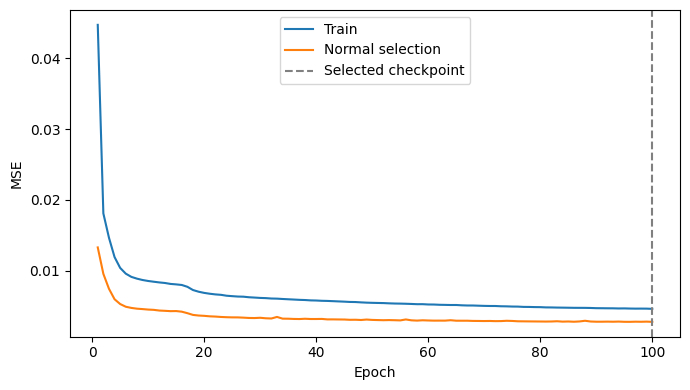

In [5]:
@torch.inference_mode()
def normal_validation():
    model.eval()
    total, count = 0., 0
    for x in batches(select_data):
        x = x.to(DEVICE, non_blocking=True)
        value = objective(model(x), x)
        if not bool(torch.isfinite(value)):
            raise FloatingPointError('Normal-selection loss is not finite.')
        total += float(value.item()) * len(x)
        count += len(x)
    return total / count


def early_stopping_update(value, anchor, stale):
    """Stopping anchor is independent of the absolute-best checkpoint."""
    if not np.isfinite(value):
        raise FloatingPointError('Normal-selection loss is not finite.')
    improvement = max(EARLY_STOPPING_MIN_DELTA,
                      EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT * abs(anchor))
    if not np.isfinite(anchor) or anchor - value > improvement:
        return float(value), 0
    return float(anchor), int(stale) + 1


optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY,
                             betas=(.9, .999), eps=1e-8, foreach=False)
history = []
validated_epochs, completed_steps = 0, 0
best_value, best_epoch = float('inf'), 0
stop_anchor, stale = float('inf'), 0
TRAINING_COMPLETE = False


def training_checkpoint():
    # Epoch-bound recovery is deterministic: each epoch reseeds its crop order.
    return dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                epoch=validated_epochs, optimizer_steps=completed_steps,
                best=best_value, best_epoch=best_epoch,
                stop_anchor=stop_anchor, stale=stale, history=history,
                config_sha256=digest(config))


if (RUN / 'last.pt').exists():
    state = load_pt(RUN / 'last.pt')
    if state['config_sha256'] != digest(config):
        raise RuntimeError('Resume checkpoint does not match this exact new experiment.')
    model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    validated_epochs = int(state['epoch'])
    completed_steps = int(state['optimizer_steps'])
    history = state['history']
    best_value, best_epoch = float(state['best']), int(state['best_epoch'])
    stop_anchor, stale = float(state['stop_anchor']), int(state['stale'])
    if not (0 <= validated_epochs <= EPOCHS):
        raise RuntimeError('Resume epoch is outside the new experiment cap.')
    if completed_steps != validated_epochs * STEPS_PER_EPOCH or len(history) != validated_epochs:
        raise RuntimeError('Resume training history/step count is inconsistent.')
    if validated_epochs and not (RUN / 'best.pt').is_file():
        raise FileNotFoundError('Resume requires the corresponding best.pt checkpoint.')
    del state
    print('Resuming the new shared100 run after epoch', validated_epochs)


def train_to_completion():
    global validated_epochs, completed_steps, best_value, best_epoch
    global stop_anchor, stale, TRAINING_COMPLETE
    if validated_epochs >= EPOCHS or stale >= EARLY_STOPPING_PATIENCE:
        TRAINING_COMPLETE = True
        return
    for epoch in range(validated_epochs + 1, EPOCHS + 1):
        previous = [float(h['epoch_seconds']) for h in history[-10:]]
        # A clean epoch is started only with time for its update/validation/save.
        estimate = max(previous or [60.]) * 1.5
        session_guard(estimate)
        begin = time.monotonic()
        seed_all(SEED + epoch)
        model.train()
        total, count, epoch_steps = 0., 0, 0
        for x in batches(train_data, True, epoch):
            x = x.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            value = objective(model(x), x)
            if not bool(torch.isfinite(value)):
                raise FloatingPointError('Training loss is not finite.')
            value.backward()
            optimizer.step()
            total += float(value.item()) * len(x)
            count += len(x)
            epoch_steps += 1
        if count != PATCH_COUNT or epoch_steps != STEPS_PER_EPOCH:
            raise RuntimeError('A training epoch must expose every fixed training patch once.')
        normal_loss = float(normal_validation())
        # The absolute lowest observed normal loss chooses the evaluated checkpoint.
        if normal_loss < best_value:
            best_value, best_epoch = normal_loss, epoch
            save_pt(dict(model=model.state_dict(), epoch=epoch,
                         normal_selection_loss=best_value,
                         config_sha256=digest(config)), RUN / 'best.pt')
        stop_anchor, stale = early_stopping_update(normal_loss, stop_anchor, stale)
        validated_epochs = epoch
        completed_steps += epoch_steps
        elapsed = time.monotonic() - begin
        row = dict(epoch=epoch, train_loss=total/count,
                   normal_selection_loss=normal_loss, best_epoch=best_epoch,
                   stopping_anchor=stop_anchor, stale_epochs=stale,
                   optimizer_steps=completed_steps, epoch_seconds=elapsed)
        row[TRAIN_LOSS_COLUMN] = total/count
        row[SELECTION_LOSS_COLUMN] = normal_loss
        history.append(row)
        save_pt(training_checkpoint(), RUN / 'last.pt')
        pd.DataFrame(history).to_csv(RUN / 'training_history.csv', index=False)
        write_json(RUN / 'status.json', dict(status='training',
                   completed_epochs=validated_epochs, max_epochs=EPOCHS,
                   selected_epoch=best_epoch, optimizer_steps=completed_steps,
                   stale_epochs=stale, test_evaluated=False))
        report_zip()
        print(f'Epoch {epoch}/{EPOCHS}: train={total/count:.7f}, '
              f'normal_select={normal_loss:.7f}, best={best_epoch}, '
              f'patience={stale}/{EARLY_STOPPING_PATIENCE}, seconds={elapsed:.1f}', flush=True)
        if stale >= EARLY_STOPPING_PATIENCE:
            print('Stopped on normal-validation patience. Test labels were not used.')
            break
    TRAINING_COMPLETE = True


try:
    train_to_completion()
except SessionPause as exc:
    # No partial epoch is evaluated or promoted to a checkpoint.
    save_pt(training_checkpoint(), RUN / 'last.pt')
    write_json(RUN / 'status.json', dict(status='paused_during_training',
               completed_epochs=validated_epochs, max_epochs=EPOCHS,
               selected_epoch=best_epoch, optimizer_steps=completed_steps,
               test_evaluated=False, reason=str(exc)))
    print(str(exc), 'Retain this output folder. Set RESUME_DIR next session.')
    report_zip()
except BaseException:
    report_zip()
    raise


if TRAINING_COMPLETE:
    save_pt(dict(model=model.state_dict(), epoch=validated_epochs,
                 config_sha256=digest(config)), RUN / 'final.pt')
    selected = load_pt(RUN / 'best.pt')
    if selected['config_sha256'] != digest(config):
        raise RuntimeError('Best checkpoint belongs to a different experiment.')
    model.load_state_dict(selected['model'])
    model.eval()
    best_epoch, best_value = int(selected['epoch']), float(selected['normal_selection_loss'])
    selected_steps = best_epoch * STEPS_PER_EPOCH
    stop_reason = ('normal_patience' if stale >= EARLY_STOPPING_PATIENCE
                   else 'maximum_epoch_cap')
    exposure.update(completed_epochs=validated_epochs, selected_epoch=best_epoch,
                    optimizer_steps=completed_steps, selected_checkpoint_optimizer_steps=selected_steps,
                    crop_presentations=validated_epochs * PATCH_COUNT,
                    selected_checkpoint_crop_presentations=best_epoch * PATCH_COUNT,
                    stop_reason=stop_reason)
    write_json(RUN / 'training_exposure.json', exposure)
    write_json(RUN / 'selected_checkpoint.json', dict(
        epoch=best_epoch, normal_selection_loss=best_value,
        sha256=sha(RUN / 'best.pt'), trained_epochs=validated_epochs,
        max_epochs=EPOCHS, optimizer_steps=completed_steps,
        selected_checkpoint_optimizer_steps=selected_steps,
        early_stopping_patience=EARLY_STOPPING_PATIENCE, stop_reason=stop_reason))
    del selected
    history_df = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(history_df.epoch, history_df.train_loss, label='Train')
    ax.plot(history_df.epoch, history_df.normal_selection_loss, label='Normal selection')
    ax.axvline(best_epoch, color='gray', linestyle='--', label='Selected checkpoint')
    ax.set(xlabel='Epoch', ylabel=LOSS_LABEL)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN / 'training_curve.png', dpi=150)
    plt.show()
    report_zip()
else:
    print('Training is incomplete; calibration and test evaluation are skipped.')


## 6. Normal-only calibration and model lock

Historical thresholding reproduces the existing comparison: Q3 + 4×IQR over all normal
validation score pixels. Because audit contributes, that historical FPR is not independent.
The other rows calibrate on the calibration role only and audit the holdout role.
Scores and thresholds are locked before test masks are decoded.


In [6]:
STRUCT = generate_binary_structure(2, 2)


def postprocess(mask):
    m = binary_closing(mask, structure=STRUCT, iterations=2)
    m = binary_opening(m, structure=STRUCT, iterations=1)
    m = binary_fill_holes(m)
    cc, _ = label(m)
    keep = np.bincount(cc.ravel()) >= 50
    keep[0] = False
    return binary_opening(keep[cc], structure=STRUCT, iterations=2)


def score_maps(role):
    session_guard()
    selected_hash = sha(RUN / 'best.pt')
    directory = CACHE / ('scores_' + selected_hash[:16])
    directory.mkdir(exist_ok=True)
    shape = (len(splits[role]), SIZE, SIZE)
    paths = {s:directory/f'{s}_{role}.npy' for s in SCORES}
    work = {s:p.with_name(p.stem+'.work.npy') for s,p in paths.items()}
    cursor = directory / f'{role}_progress.json'
    identity = dict(config_sha256=digest(config), checkpoint_sha256=selected_hash,
                    role=role, shape=list(shape), scores=list(SCORES))
    position = 0
    if cursor.exists():
        previous = json.loads(cursor.read_text())
        if previous.get('identity') != identity:
            raise RuntimeError('Cached scores belong to a different experiment.')
        position = int(previous['next_frame'])
    elif any(p.exists() for p in [*paths.values(), *work.values()]):
        raise RuntimeError('Score files without matching recovery metadata; use a fresh RUN.')
    if not 0 <= position <= shape[0]:
        raise RuntimeError('Invalid score recovery cursor.')
    if not (position == shape[0] and all(p.exists() for p in paths.values())):
        arrays = {}
        for s in SCORES:
            candidate = paths[s] if paths[s].exists() else work[s]
            if candidate.exists():
                arrays[s] = np.lib.format.open_memmap(candidate, mode='r+')
            elif position == 0:
                arrays[s] = np.lib.format.open_memmap(work[s], mode='w+',
                            dtype=np.float32, shape=shape)
            else:
                raise RuntimeError('Partial scoring metadata exists without its .work.npy file.')
            if arrays[s].shape != shape or arrays[s].dtype != np.float32:
                raise RuntimeError('Cached score shape/dtype mismatch.')
        write_json(cursor, dict(identity=identity, next_frame=position))
        data = cache_images(role)
        try:
            for i in tqdm(range(position, len(data)), desc='Reconstruct '+role):
                session_guard()
                original = data[i].astype(np.float32)/255
                reconstruction = reconstruct(model, data[i])
                residual = original - reconstruction
                values = raw_score_maps(original, reconstruction, residual)
                for s in SCORES:
                    score = gaussian_filter(values[s], sigma=1).astype(np.float32)
                    if not np.isfinite(score).all():
                        raise FloatingPointError('Anomaly map is not finite.')
                    arrays[s][i] = score
                position = i + 1
                if position % 50 == 0:
                    for array in arrays.values(): array.flush()
                    write_json(cursor, dict(identity=identity, next_frame=position))
        except SessionPause:
            for array in arrays.values(): array.flush()
            write_json(cursor, dict(identity=identity, next_frame=position))
            arrays.clear()
            raise
        for array in arrays.values(): array.flush()
        arrays.clear()
        write_json(cursor, dict(identity=identity, next_frame=position))
        for s in SCORES:
            if work[s].exists(): work[s].replace(paths[s])
    result = {s:np.load(p, mmap_mode='r') for s,p in paths.items()}
    for array in result.values():
        if array.shape != shape or array.dtype != np.float32:
            raise RuntimeError('Completed score cache shape/dtype mismatch.')
        for frame in array:
            if not np.isfinite(frame).all():
                raise FloatingPointError('Completed score cache contains nonfinite values.')
    return result


EVALUATION_READY = False
maps, thresholds = {}, {}
if TRAINING_COMPLETE:
    try:
        maps = {role:score_maps(role) for role in ('select', 'calibrate', 'audit')}
        audit_rows = []
        for s in SCORES:
            session_guard(60.)
            values = np.concatenate([maps[r][s].ravel() for r in ('select','calibrate','audit')])
            q1, q3 = np.percentile(values, [25, 75])
            thresholds[s] = {'historical':float(q3 + 4*(q3-q1))}
            del values
            rng = np.random.default_rng(SEED + 71)
            sample = np.concatenate([a.ravel()[rng.choice(SIZE*SIZE, 4096, replace=False)]
                                     for a in maps['calibrate'][s]])
            for target in FPRS:
                thresholds[s][f'fpr_{target:g}'] = float(np.quantile(sample, 1-target, method='higher'))
            for protocol, threshold in thresholds[s].items():
                raw, processed = [], []
                for score in maps['audit'][s]:
                    session_guard()
                    prediction = score > threshold
                    raw.append(float(prediction.mean()))
                    processed.append(float(postprocess(prediction).mean()))
                audit_rows.append(dict(score=s, protocol=protocol, threshold=threshold,
                    audit_raw_fpr=float(np.mean(raw)), audit_post_fpr=float(np.mean(processed)),
                    audit_used_in_threshold=(protocol == 'historical')))
        write_json(RUN / 'thresholds_LOCKED.json', thresholds)
        audit = pd.DataFrame(audit_rows)
        audit.to_csv(RUN / 'normal_fpr.csv', index=False)
        write_json(RUN / 'evaluation_lock.json', dict(
            config_sha256=digest(config), checkpoint_sha256=sha(RUN / 'best.pt'),
            thresholds_sha256=sha(RUN / 'thresholds_LOCKED.json'),
            selected_epoch=best_epoch, selection='normal-validation loss only',
            test_labels_used_for_selection=False))
        EVALUATION_READY = True
        print('Both prescribed scores and their normal-only thresholds are locked before reading test masks.')
        display(audit)
    except SessionPause as exc:
        write_json(RUN / 'status.json', dict(status='paused_during_calibration',
            completed_epochs=validated_epochs, selected_epoch=best_epoch,
            optimizer_steps=completed_steps, test_evaluated=False, reason=str(exc)))
        print(str(exc), 'Keep the output folder including _cache; set RESUME_DIR next session.')
        report_zip()


Reconstruct select:   0%|          | 0/521 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Reconstruct calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

Reconstruct audit:   0%|          | 0/234 [00:00<?, ?it/s]

Both prescribed scores and their normal-only thresholds are locked before reading test masks.


,score,protocol,threshold,audit_raw_fpr,audit_post_fpr,audit_used_in_threshold
0,shared_mae,historical,0.104487,0.075208,0.072792,True
1,shared_mae,fpr_0.005,0.207716,0.007542,0.001596,False
2,shared_mae,fpr_0.01,0.177224,0.014976,0.006094,False
3,shared_mae,fpr_0.02,0.147563,0.029058,0.018228,False
4,shared_mae,fpr_0.05,0.106237,0.072431,0.069515,False
5,shared_mae,fpr_0.1,0.074021,0.144086,0.155665,False
6,squared_error,historical,0.004011,0.226139,0.242289,True
7,squared_error,fpr_0.005,0.057731,0.007393,0.001254,False
8,squared_error,fpr_0.01,0.042924,0.014985,0.005215,False
9,squared_error,fpr_0.02,0.030541,0.029240,0.016684,False


## 7. Common foreground IoU and other metrics

`mean_iou` and `mean_frame_iou` are identical foreground/anomaly frame-averaged IoU.
Pooled IoU is separate. Both raw and common-morphology masks are evaluated on all 496
test frames. The report adds Dice, precision, recall, full-pixel AP/AUROC/AUPRO and
per-video results. Ranking metrics use continuous maps before morphology.


In [7]:
def confusion(pred, target):
    return (int(np.count_nonzero(pred & target)), int(np.count_nonzero(pred & ~target)),
            int(np.count_nonzero(~pred & target)), int(np.count_nonzero(~pred & ~target)))


def iou(tp, fp, fn):
    return tp / (tp + fp + fn) if tp + fp + fn else 1.0


def dice(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0


def pixel_ranking(scores, masks):
    # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
    # PRO gives every 8-connected GT region equal weight, integrates FPR<=0.30,
    # and normalizes by 0.30. Test labels here calculate metrics, not thresholds.
    y = np.asarray(masks, dtype=np.bool_).ravel()
    score = np.asarray(scores, dtype=np.float32).ravel()
    positives, negatives = int(y.sum()), int((~y).sum())
    if positives == 0 or negatives == 0:
        return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                    gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
    weights = np.zeros(masks.shape, dtype=np.float32)
    regions = 0
    for i, m in enumerate(masks):
        cc, n = label(m, structure=STRUCT)
        areas = np.bincount(cc.ravel())
        lookup = np.zeros(len(areas), dtype=np.float32)
        lookup[1:] = 1. / areas[1:]
        weights[i] = lookup[cc]
        regions += n
    order = np.argsort(score, kind='stable')[::-1]
    sorted_scores = score[order]
    ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
    del sorted_scores
    cumsum = np.cumsum(y[order], dtype=np.int64)
    tp = cumsum[ends].astype(np.float64)
    del cumsum
    fp = (ends + 1).astype(np.float64) - tp
    ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
    fpr = np.r_[0., fp / negatives]
    tpr = np.r_[0., tp / positives]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    auroc = float(trapz(tpr, fpr))
    del tp, fp, tpr
    region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
    pro = np.r_[0., region_cumsum[ends] / regions]
    del region_cumsum, weights, order, ends
    cap = .30
    # Keep all vertical segments at a repeated FPR; interpolate the crossing segment.
    right = int(np.searchsorted(fpr, cap, side='right'))
    xx, yy = fpr[:right], pro[:right]
    if xx[-1] < cap:
        upper = right
        endpoint = yy[-1] + (pro[upper] - yy[-1]) * (cap - xx[-1]) / (fpr[upper] - xx[-1])
        xx = np.r_[xx, cap]
        yy = np.r_[yy, endpoint]
    aupro = float(trapz(yy, xx) / cap)
    return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)


def evaluate_test():
    # Check the lock before accessing any test label content.
    lock = json.loads((RUN / 'evaluation_lock.json').read_text())
    assert lock['config_sha256'] == digest(config)
    assert lock['checkpoint_sha256'] == sha(RUN / 'best.pt')
    assert lock['thresholds_sha256'] == sha(RUN / 'thresholds_LOCKED.json')
    maps['test'] = score_maps('test')
    gt = np.lib.format.open_memmap(CACHE / 'test_masks.npy', mode='w+', dtype=np.bool_,
                                 shape=(len(splits['test']), SIZE, SIZE))
    mask_hashes = []
    for i, r in enumerate(tqdm(splits['test'], desc='Decode test masks after lock')):
        session_guard()
        with Image.open(r['mask']) as im:
            gt[i] = np.asarray(im.convert('L').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                               dtype=np.float32) / 255 > .5
        mask_hashes.append(dict(relative=r['relative'], sha256=sha(r['mask'])))
    gt.flush()
    assert gt.any() and not gt.all()
    write_json(RUN / 'mask_hashes.json', mask_hashes)
    rows = []
    for s in SCORES:
        for protocol, t in tqdm(thresholds[s].items(), desc='Masks ' + s):
            session_guard(30.)
            for i, r in enumerate(splits['test']):
                raw = maps['test'][s][i] > t
                for processing, pred in [('raw', raw), ('postprocessed', postprocess(raw))]:
                    tp, fp, fn, tn = confusion(pred, gt[i])
                    rows.append(dict(score=s, protocol=protocol, processing=processing,
                                     relative=r['relative'], video=r['video'], tp=tp, fp=fp, fn=fn, tn=tn,
                                     iou=iou(tp, fp, fn), dice=dice(tp, fp, fn),
                                     precision=tp / (tp + fp) if tp + fp else 0.,
                                     recall=tp / (tp + fn) if tp + fn else 0.))
    frames = pd.DataFrame(rows)
    frames.to_csv(RUN / 'test_frame_metrics.csv', index=False)
    keys = ['score', 'protocol', 'processing']
    summaries = []
    for (s, protocol, processing), group in frames.groupby(keys, sort=False):
        tp, fp, fn, tn = [int(group[c].sum()) for c in ('tp', 'fp', 'fn', 'tn')]
        a = audit[(audit.score == s) & (audit.protocol == protocol)].iloc[0]
        summaries.append(dict(
            model=MODEL_LABEL, score=s, protocol=protocol, processing=processing,
            mean_frame_iou=float(group.iou.mean()), mean_iou=float(group.iou.mean()),
            median_frame_iou=float(group.iou.median()), mean_frame_dice=float(group.dice.mean()),
            mean_frame_precision=float(group.precision.mean()), mean_frame_recall=float(group.recall.mean()),
            pooled_iou=iou(tp, fp, fn), pooled_dice=dice(tp, fp, fn),
            pooled_precision=tp / (tp + fp) if tp + fp else 0.,
            pooled_recall=tp / (tp + fn) if tp + fn else 0.,
            audit_raw_fpr=float(a.audit_raw_fpr), audit_post_fpr=float(a.audit_post_fpr),
            audit_used_in_threshold=bool(a.audit_used_in_threshold), threshold=float(a.threshold),
            n_frames=len(group), total_parameters=PARAMETERS, selected_epoch=best_epoch,
            completed_epochs=validated_epochs, max_epochs=EPOCHS, optimizer_steps=completed_steps,
            selected_checkpoint_optimizer_steps=selected_steps,
            training_unit='fixed 128x128 RGB crop bank', training_samples_per_epoch=PATCH_COUNT,
            crop_presentations=validated_epochs*PATCH_COUNT,
            distinct_training_frames=int(table.image_index.nunique()),
            available_training_frames=len(splits['train']),
            early_stopping_patience=EARLY_STOPPING_PATIENCE, stop_reason=stop_reason,
            normal_selection_loss=best_value,
            training_validation_seconds=float(history_df.epoch_seconds.sum()),
            trainable_parameters=TRAINABLE_PARAMETERS, frozen_parameters=FROZEN_PARAMETERS,
        ))
    summary = pd.DataFrame(summaries)
    summary.to_csv(RUN / 'summary.csv', index=False)
    frames.groupby(keys + ['video'], as_index=False).agg(
        mean_frame_iou=('iou', 'mean'), mean_frame_dice=('dice', 'mean'),
        frames=('iou', 'size')).to_csv(RUN / 'test_video_metrics.csv', index=False)
    ranking = []
    for s in SCORES:
        session_guard(600.)
        print('Exact full-pixel AP / AUROC / AUPRO:', s, flush=True)
        ranking.append(dict(score=s, **pixel_ranking(maps['test'][s], gt)))
    ranking = pd.DataFrame(ranking)
    ranking.to_csv(RUN / 'full_pixel_ranking.csv', index=False)
    headline = summary[(summary.processing == 'postprocessed') &
                       summary.protocol.isin(['historical', 'fpr_0.02'])].merge(ranking, on='score')
    headline.to_csv(RUN / 'headline_metrics.csv', index=False)
    print('Historical comparison: each prescribed score / historical / postprocessed / mean_frame_iou')
    display(headline[['score', 'protocol', 'mean_frame_iou', 'mean_frame_dice',
                      'pooled_precision', 'pooled_recall', 'pixel_ap', 'pixel_auroc', 'audit_post_fpr']])
    # Shared auxiliary image score: top1% mean map intensity (not from the AE paper).
    # Do not mix independent audit frames into the test set just to manufacture negatives.
    from sklearn.metrics import average_precision_score, roc_auc_score
    image_rows, image_ranking = [], []
    for s in SCORES:
        image_scores = []
        for a in maps['test'][s]:
            flat = np.asarray(a).ravel()
            k = max(1, int(len(flat) * .01))
            image_scores.append(float(np.partition(flat, len(flat)-k)[-k:].mean()))
        image_labels = np.asarray([bool(m.any()) for m in gt], dtype=np.int64)
        for i, r in enumerate(splits['test']):
            image_rows.append(dict(score=s, relative=r['relative'], video=r['video'],
                image_score=image_scores[i], mask_has_anomaly=int(image_labels[i])))
        valid = len(np.unique(image_labels)) == 2
        image_ranking.append(dict(score=s, normal_frames=int((image_labels==0).sum()),
            anomalous_frames=int((image_labels==1).sum()),
            image_ap=float(average_precision_score(image_labels, image_scores)) if valid else None,
            image_auroc=float(roc_auc_score(image_labels, image_scores)) if valid else None,
            note='shared auxiliary top1% image score; labels from evaluated masks' if valid else
                 'Undefined discrimination: test split does not contain both image classes.'))
    pd.DataFrame(image_rows).to_csv(RUN / 'test_image_scores.csv', index=False)
    write_json(RUN / 'image_ranking.json', image_ranking)
    return gt, frames, summary, ranking, headline


EVALUATION_COMPLETE = False
if EVALUATION_READY:
    try:
        gt, frames, summary, ranking, headline = evaluate_test()
        EVALUATION_COMPLETE = True
    except SessionPause as exc:
        write_json(RUN/'status.json', dict(status='paused_during_evaluation',
            completed_epochs=validated_epochs, selected_epoch=best_epoch,
            optimizer_steps=completed_steps, test_evaluated=False, reason=str(exc)))
        print(str(exc), 'Keep best.pt, last.pt, config.json and _cache; resume with identical settings.')
        report_zip()


Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

Reconstruct test:   0%|          | 0/496 [00:00<?, ?it/s]

Decode test masks after lock:   0%|          | 0/496 [00:00<?, ?it/s]

Masks shared_mae:   0%|          | 0/6 [00:00<?, ?it/s]

Masks squared_error:   0%|          | 0/6 [00:00<?, ?it/s]

Exact full-pixel AP / AUROC / AUPRO: shared_mae
Exact full-pixel AP / AUROC / AUPRO: squared_error
Historical comparison: each prescribed score / historical / postprocessed / mean_frame_iou


,score,protocol,mean_frame_iou,mean_frame_dice,pooled_precision,pooled_recall,pixel_ap,pixel_auroc,audit_post_fpr
0,shared_mae,historical,0.333253,0.492509,0.450188,0.583087,0.372868,0.796315,0.072792
1,shared_mae,fpr_0.02,0.191322,0.314514,0.529057,0.231246,0.372868,0.796315,0.018228
2,squared_error,historical,0.255723,0.400009,0.265477,0.936641,0.380684,0.813173,0.242289
3,squared_error,fpr_0.02,0.171649,0.286508,0.527171,0.202984,0.380684,0.813173,0.016684


## 8. Fixed examples and return files

Fixed manifest indices produce examples for historical and FPR=0.02 thresholds.
`headline_metrics.csv` joins the main rows with threshold-free metrics and training
metadata. Send the compact report ZIP and the log; retain all weights and caches.


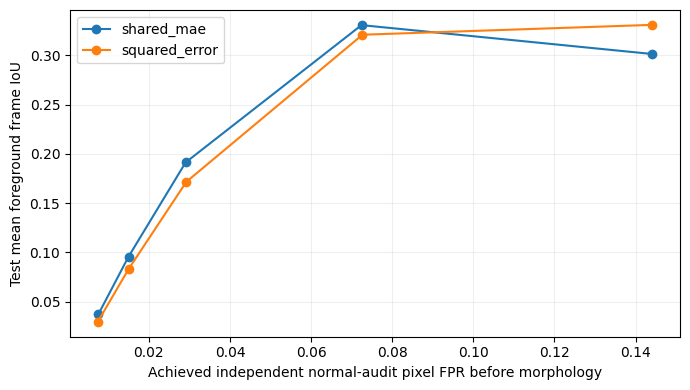

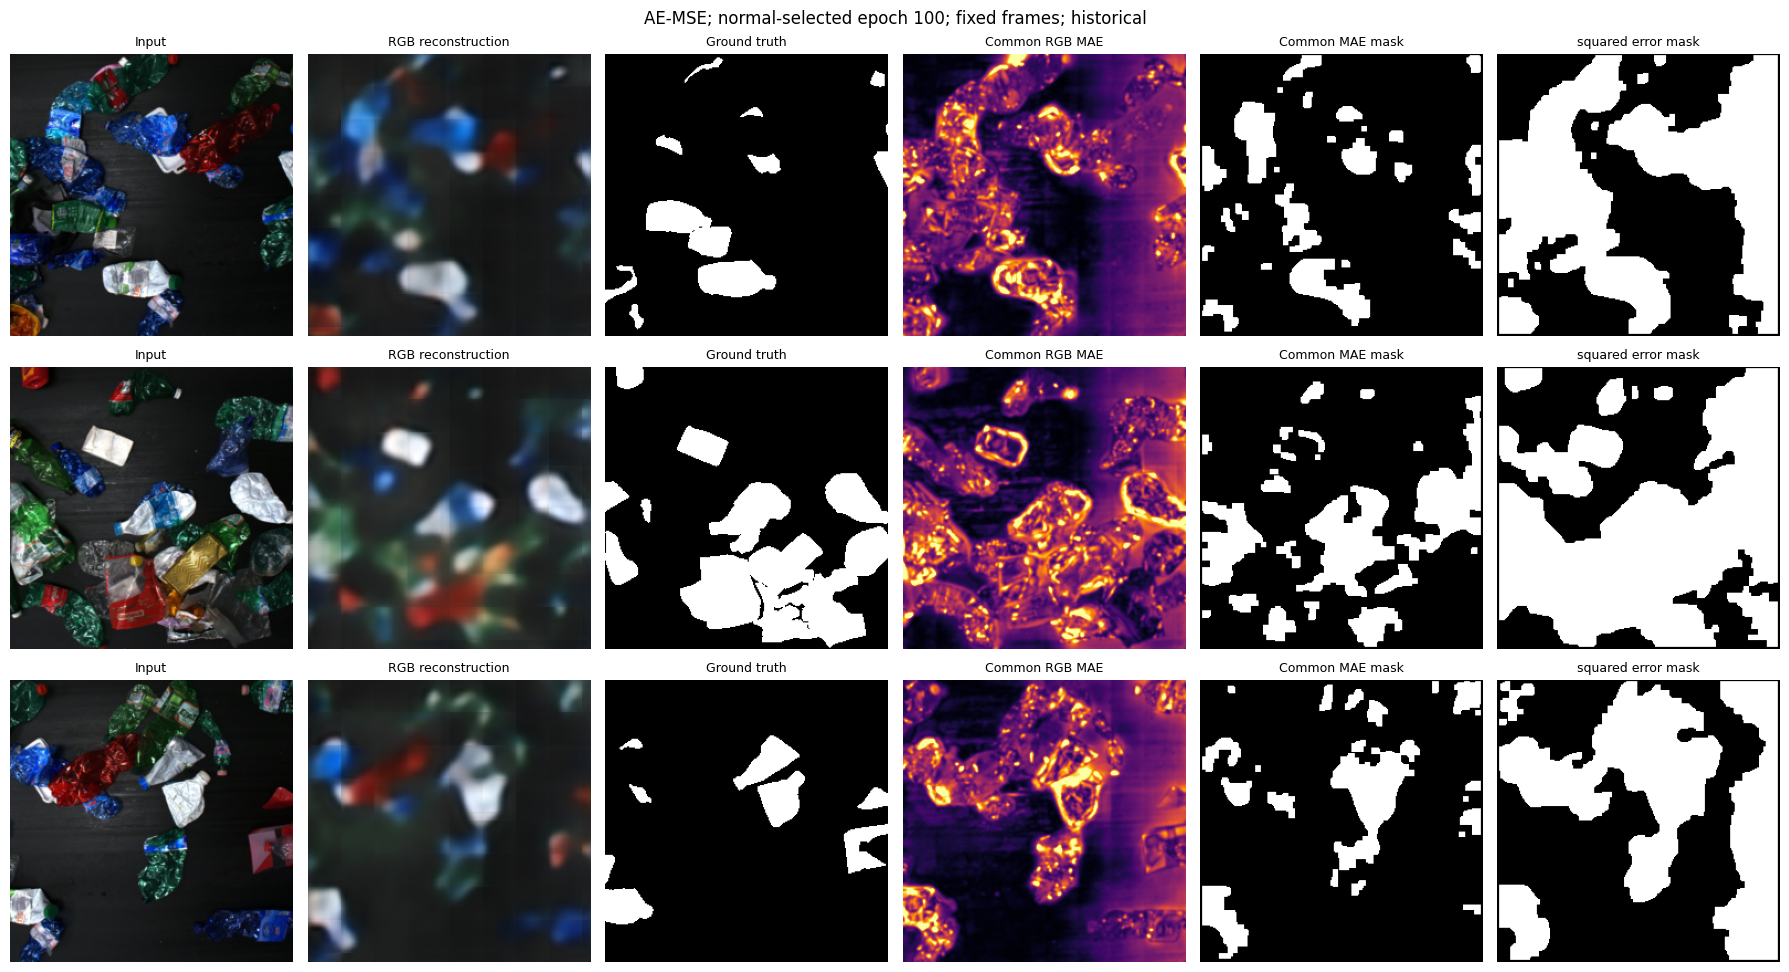

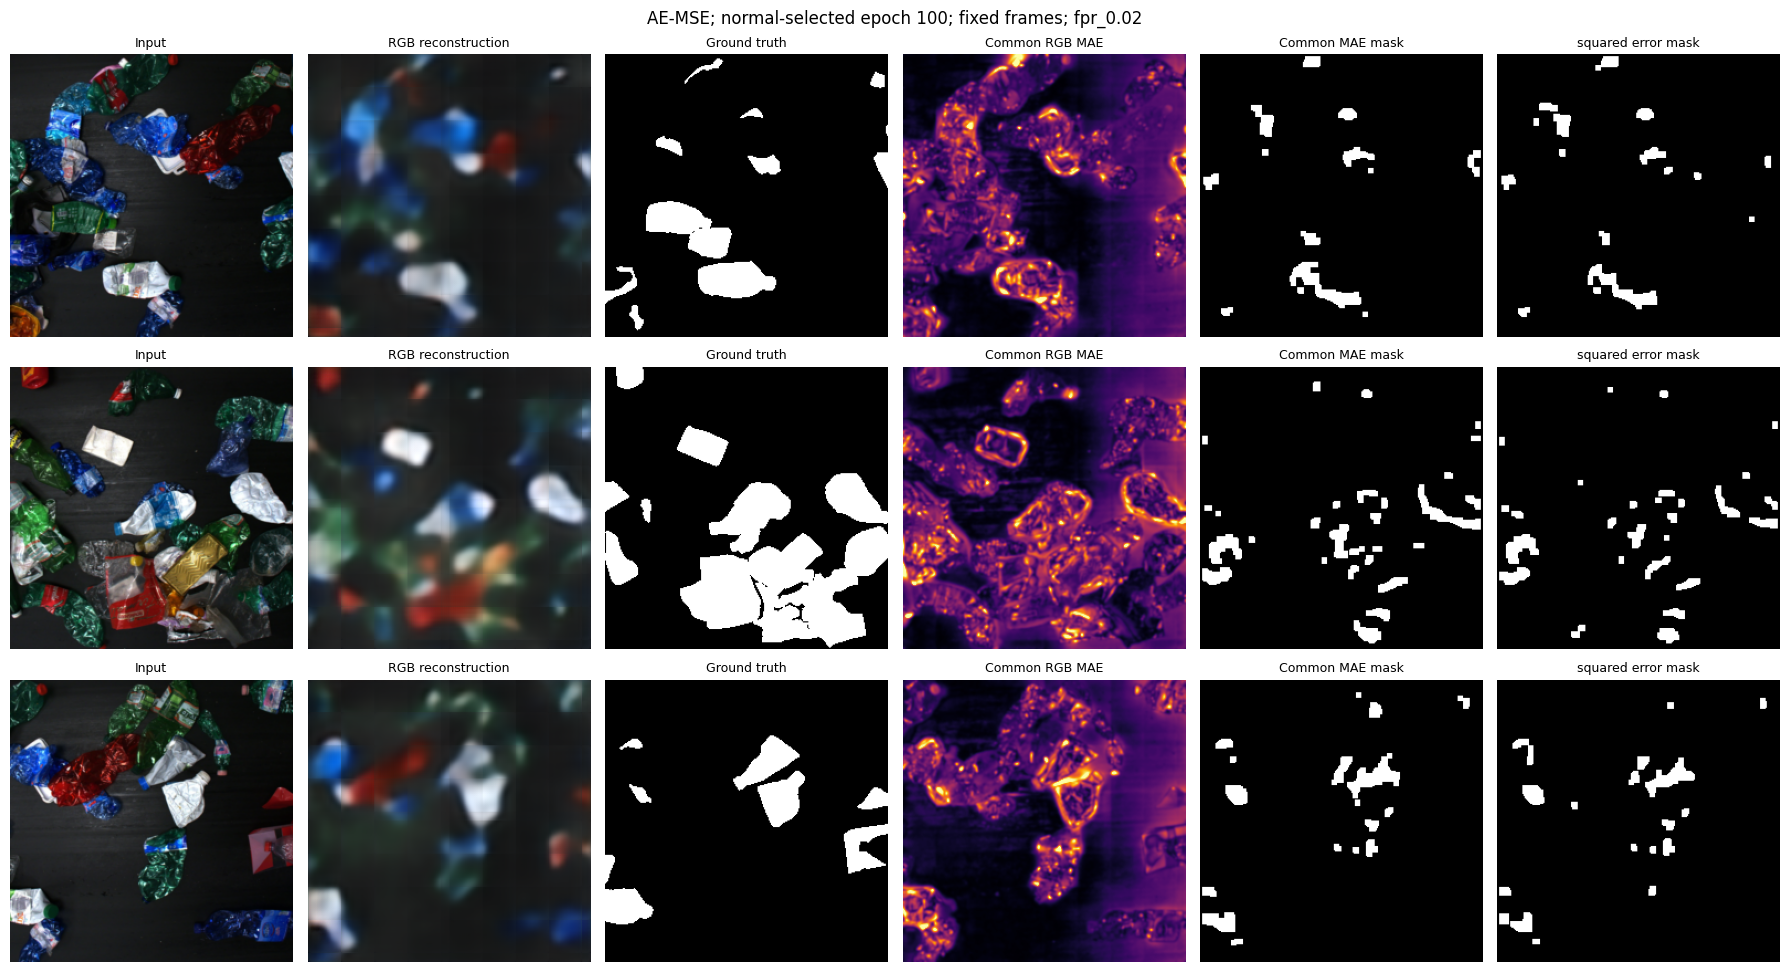

AE-MSE: WS2 shared100 comparison, baseline 1

Primary architecture/training source:
https://arxiv.org/pdf/1807.02011 (Bergmann et al., 2019, Table 1 and Section 4.2).
The original paper uses grayscale, 200 epochs and its own threshold/morphology evaluation.
This is a declared RGB WS2 adaptation under the new common 100-epoch cap, not a claim
to duplicate the paper's entire original experiment or released author code.

Preserved: nine-layer strided convolutional encoder, reverse convolution-transpose decoder,
LeakyReLU slope 0.2, linear encoder/decoder outputs, 500-dimensional bottleneck,
10,000 fixed normal 128x128 training patches from full images resized to 256x256,
batch 64, last short batch retained, float32 without AMP/TF32,
Adam LR 0.0002 / betas (0.9,0.999) / eps 1e-8 / weight_decay 0.00001, no LR scheduler,
stride 30 sliding-patch reconstruction with overlap averaging and full edge coverage.
Unchanged score definitions: common RGB MAE and squared error, with Gaussian sigma 1.
T

,model,score,protocol,processing,mean_frame_iou,mean_iou,median_frame_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,...,normal_selection_loss,training_validation_seconds,trainable_parameters,frozen_parameters,pixel_ap,pixel_auroc,pixel_aupro_0p30,gt_regions,positive_pixels,negative_pixels
0,AE-MSE,shared_mae,historical,postprocessed,0.333253,0.333253,0.334034,0.492509,0.441798,0.585155,...,0.002752,781.639184,2689399,0,0.372868,0.796315,0.504043,3688,4732744,27773112
1,AE-MSE,shared_mae,fpr_0.02,postprocessed,0.191322,0.191322,0.188218,0.314514,0.518509,0.235359,...,0.002752,781.639184,2689399,0,0.372868,0.796315,0.504043,3688,4732744,27773112
2,AE-MSE,squared_error,historical,postprocessed,0.255723,0.255723,0.254129,0.400009,0.260777,0.934262,...,0.002752,781.639184,2689399,0,0.380684,0.813173,0.527095,3688,4732744,27773112
3,AE-MSE,squared_error,fpr_0.02,postprocessed,0.171649,0.171649,0.165502,0.286508,0.516541,0.206467,...,0.002752,781.639184,2689399,0,0.380684,0.813173,0.527095,3688,4732744,27773112


/kaggle/working/AE_MSE_baseline_1_shared100_report.zip

Retain the complete output folder. Initially return this report ZIP and the notebook log.


In [8]:
def final_report():
    fig, ax = plt.subplots(figsize=(7, 4))
    for s in SCORES:
        data = summary[(summary.score == s) & (summary.processing == 'postprocessed') &
                       (summary.protocol != 'historical')].sort_values('audit_raw_fpr')
        ax.plot(data.audit_raw_fpr, data.mean_frame_iou, 'o-', label=s)
    ax.set(xlabel='Achieved independent normal-audit pixel FPR before morphology',
           ylabel='Test mean foreground frame IoU')
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(RUN / 'iou_vs_fpr.png', dpi=150)
    plt.show()
    indices = np.linspace(0, len(splits['test']) - 1, 3, dtype=int)
    data = cache_images('test')
    for protocol in ('historical', 'fpr_0.02'):
        fig, axes = plt.subplots(3, 6, figsize=(18, 10))
        first, native = thresholds[SCORES[0]][protocol], thresholds[SCORES[1]][protocol]
        for row, idx in enumerate(indices):
            session_guard()
            reconstruction = reconstruct(model, data[idx])
            panels = [(data[idx], 'Input', None),
                (np.clip(reconstruction, 0, 1), 'RGB reconstruction', None),
                (gt[idx], 'Ground truth', 'gray'),
                (maps['test'][SCORES[0]][idx], 'Common RGB MAE', 'inferno'),
                (postprocess(maps['test'][SCORES[0]][idx] > first), 'Common MAE mask', 'gray'),
                (postprocess(maps['test'][SCORES[1]][idx] > native), NATIVE_LABEL+' mask', 'gray')]
            for col, (array, title, cmap) in enumerate(panels):
                axes[row, col].imshow(array, cmap=cmap, vmin=0 if col == 3 else None,
                                     vmax=max(2*first, 1e-8) if col == 3 else None)
                axes[row, col].set_title(title, fontsize=9)
                axes[row, col].axis('off')
        fig.suptitle(f'{MODEL_LABEL}; normal-selected epoch {best_epoch}; fixed frames; {protocol}')
        fig.tight_layout()
        fig.savefig(RUN / f'fixed_examples_{protocol}.png', dpi=150)
        plt.show()
    write_json(RUN / 'fixed_examples.json', [splits['test'][int(i)]['relative'] for i in indices])
    write_json(RUN / 'status.json', dict(status='complete', model=MODEL_LABEL,
        completed_epochs=validated_epochs, max_epochs=EPOCHS,
        selected_epoch=best_epoch, normal_selection_loss=best_value,
        optimizer_steps=completed_steps, selected_checkpoint_optimizer_steps=selected_steps,
        stop_reason=stop_reason, training_unit='fixed 128x128 RGB crop bank',
        training_samples_per_epoch=PATCH_COUNT, crop_presentations=PATCH_COUNT*validated_epochs,
        distinct_training_frames=int(table.image_index.nunique()),
        available_training_frames=len(splits['train']),
        total_parameters=PARAMETERS, trainable_parameters=PARAMETERS, frozen_parameters=0,
        training_validation_seconds=float(history_df.epoch_seconds.sum()),
        test_evaluated=True, peak_gpu_allocated_bytes=torch.cuda.max_memory_allocated()))
    text = f'''{MODEL_LABEL}: WS2 shared100 comparison, baseline {BASELINE_NUMBER}

Primary architecture/training source:
https://arxiv.org/pdf/1807.02011 (Bergmann et al., 2019, Table 1 and Section 4.2).
The original paper uses grayscale, 200 epochs and its own threshold/morphology evaluation.
This is a declared RGB WS2 adaptation under the new common 100-epoch cap, not a claim
to duplicate the paper's entire original experiment or released author code.

Preserved: nine-layer strided convolutional encoder, reverse convolution-transpose decoder,
LeakyReLU slope 0.2, linear encoder/decoder outputs, 500-dimensional bottleneck,
10,000 fixed normal 128x128 training patches from full images resized to 256x256,
batch 64, last short batch retained, float32 without AMP/TF32,
Adam LR 0.0002 / betas (0.9,0.999) / eps 1e-8 / weight_decay 0.00001, no LR scheduler,
stride 30 sliding-patch reconstruction with overlap averaging and full edge coverage.
Unchanged score definitions: common RGB MAE and {NATIVE_LABEL}, with Gaussian sigma 1.
The two scores are prescribed alternatives; neither is chosen using test performance.
SSIM variant uses standard Gaussian 11x11 / sigma 1.5 and C1=.0001, C2=.0009, independent
RGB channels, valid windows for training and reflect inputs for full-size score maps.
SSIM formula source: https://www.cns.nyu.edu/~lcv/ssim/ssim_index.m

Changed since previous notebook: maximum 200 -> 100 epochs, normal validation every 5 -> every 1,
patience {EARLY_STOPPING_PATIENCE}, >0.1% meaningful improvement from an independent stopping
anchor with numerical floor 1e-8, standard report schema, additional metrics and session guard.
The absolute lowest observed normal-selection loss chooses best.pt independently of patience.
Completed {validated_epochs} epochs, selected epoch {best_epoch}, stop_reason={stop_reason}.
Completed optimizer steps {completed_steps}; selected checkpoint steps {selected_steps}.
Normal selection loss at best checkpoint={best_value}.

One epoch is one pass through the fixed 10,000-crop bank. It is NOT one pass through all
3,829 full images. Fixed bank represents {int(table.image_index.nunique())}/3,829 training frames.
Total completed crop presentations={validated_epochs*PATCH_COUNT}.
Same epoch cap does not equalize optimizer steps, viewed pixels, FLOPs, capacity,
external pretraining or inherited Christian training. Exposure is recorded explicitly.
Train/select/calibrate/audit/test split is unchanged at 3829/521/128/234/496.
Only normal training patches receive optimizer updates. Selection chooses checkpoint;
calibration chooses thresholds; audit measures false positives; test masks evaluate the lock.
Previous 200-epoch results and QMEM/Christian checkpoints are preserved separately.
This notebook does not load an old 200-epoch checkpoint into the new shared100 experiment.

Main metric: mean foreground/anomaly IoU over all 496 frames. mean_iou is its exact alias,
not pooled IoU or foreground/background two-class mIoU. Empty union IoU/Dice=1.
Historical row uses Q3 + 4*IQR over select + calibrate + audit normal pixels, then common morphology.
Its normal audit participates in thresholding and is therefore not independent.
Independent rows use calibrate-only pixel quantiles at targets {list(FPRS)} and audit-only FPR.
Use exactly the same protocol, score convention and processing across compared rows.
Mean Dice/frame precision/frame recall, pooled IoU/Dice/precision/recall, exact full-pixel
AP/AUROC and AUPRO FPR 0..0.30 are retained. AUPRO gives equal weight to 8-connected GT regions.
Continuous ranking metrics precede binary morphology. Shared auxiliary image score is
top 1% mean map intensity; image AP/AUROC are undefined if the existing test set contains
only one image class. No audit frames are added to manufacture image-level negatives.

The held-out test data have already been examined during earlier research rounds;
do not describe this as a newly blind test or infer superiority from one seed alone.
No SMOKE switch and no anomaly-supervised training are included.
Retain the whole Kaggle output folder including best.pt, last.pt, config.json and _cache.
For recovery, attach that folder as a Kaggle input and set RESUME_DIR to its root.
Resume is accepted only for this exact new configuration/data/method.
Send the report ZIP and notebook log initially; large .npy files are not needed initially.
'''
    (RUN / 'REPORT.txt').write_text(text)
    print(text)
    try:
        executed = '\n\n'.join(get_ipython().history_manager.input_hist_raw)
    except (NameError, AttributeError):
        executed = Path(__file__).read_text()
    (RUN / 'executed_cells.py').write_text(executed)


if EVALUATION_COMPLETE:
    try:
        final_report()
        display(headline)
    except SessionPause as exc:
        write_json(RUN / 'status.json', dict(status='paused_during_report',
            completed_epochs=validated_epochs, selected_epoch=best_epoch,
            optimizer_steps=completed_steps, test_evaluated=True, reason=str(exc)))
        print(str(exc), 'The metric CSVs are saved. Resume this exact run to finish report figures.')
else:
    print('Run is incomplete. Saved status/provenance is not a final benchmark result.')
report = report_zip()
display(FileLink(str(report)))
print('Retain the complete output folder. Initially return this report ZIP and the notebook log.')
